## Сравнение моделей

In [28]:
import sys
import os
sys.path.append(os.path.abspath('..'))

In [29]:
from sklearn.pipeline import Pipeline
import pandas as pd
from src.transformers import DataCleaner, NaNCatboostImputer, FeatureCreator
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import f1_score, make_scorer
from sklearn.linear_model import LogisticRegression
from src.utils import show_metrics, show_weights
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import json
from pathlib import Path
import optuna
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
import numpy as np

In [30]:
df = pd.read_csv('../data/raw/train.csv')
X = df.drop('Credit Default', axis=1)
y = df['Credit Default']

## Пайплайн препроцессинга

In [31]:
ohe_step = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                drop="first",
                sparse_output=False,
                handle_unknown="ignore",
                dtype=int, 
            ),
            ["Home Ownership", "Purpose", "Term"],
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

In [32]:
preprocessor = Pipeline(steps=[
    ('data_cleaner', DataCleaner()),
    ('one_hot_encoder', ohe_step),
    ('yicj_imputer', NaNCatboostImputer('Years in current job', 'classification')),
    ('bankruptcies_imputer', NaNCatboostImputer('Bankruptcies', 'classification')),
    ('credit_score_imputer', NaNCatboostImputer('Credit Score', 'regression')),
    ('annual_income_imputer', NaNCatboostImputer('Annual Income', 'regression')),
    ('feature_creator', FeatureCreator())
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
#X_train = preprocessor.fit_transform(X_train)
#X_test = preprocessor.transform(X_test)
#pd.set_option('display.max_columns', None)
#X_train.head(20)

## Baseline (позже)

## Логистическая регрессия

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as 

              precision    recall  f1-score   support

           0     0.8281    0.7190    0.7697      1313
           1     0.4980    0.6512    0.5644       562

    accuracy                         0.6987      1875
   macro avg     0.6630    0.6851    0.6670      1875
weighted avg     0.7291    0.6987    0.7081      1875

roc_auc_score = 0.7735199334332558


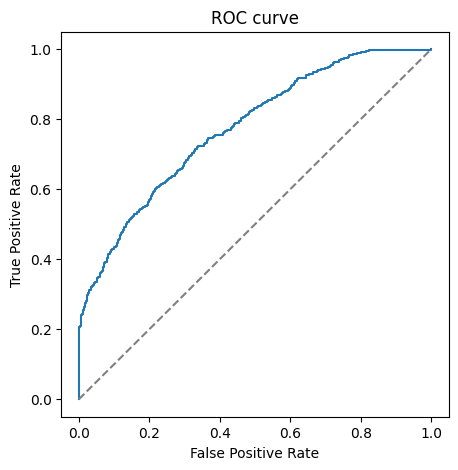

              precision    recall  f1-score   support

           0     0.8475    0.6603    0.7423      1313
           1     0.4765    0.7224    0.5743       562

    accuracy                         0.6789      1875
   macro avg     0.6620    0.6914    0.6583      1875
weighted avg     0.7363    0.6789    0.6919      1875

roc_auc_score = 0.7735199334332558


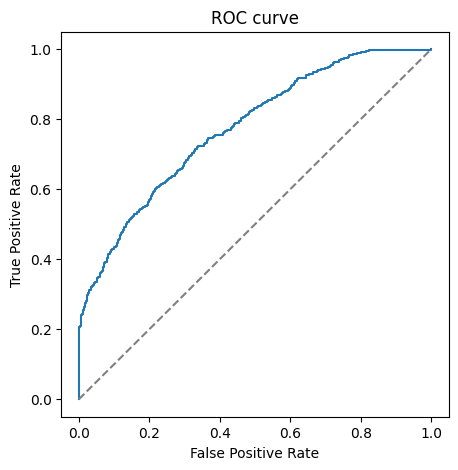

In [33]:
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler().set_output(transform='pandas')),
    ('LogisticRegression', LogisticRegression())
])
project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "LogisticRegression"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "LogisticRegression__C": optuna.distributions.FloatDistribution(0.001, 2000, log=True),
            "LogisticRegression__penalty": optuna.distributions.CategoricalDistribution(["l1", "l2"]),
            "LogisticRegression__class_weight": optuna.distributions.CategoricalDistribution([None, "balanced"]),
            "LogisticRegression__max_iter": optuna.distributions.IntDistribution(100, 1000)
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                log_reg_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("LogisticRegression__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "LogisticRegression",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

log_reg_pipeline.set_params(**{f"LogisticRegression__{k}": v for k, v in best_params_.items()})
log_reg_pipeline.fit(X_train, y_train)
y_train_pred_log_reg = log_reg_pipeline.predict(X_train)
y_train_proba_log_reg = log_reg_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_log_reg = log_reg_pipeline.predict(X_test)
y_test_proba_log_reg = log_reg_pipeline.predict_proba(X_test)[:, 1]
y_test_proba_0_log_reg = log_reg_pipeline.predict_proba(X_test)[:, 0]

#show_metrics(y_train, y_train_pred_log_reg, y_train_proba_log_reg)
show_metrics(y_test, y_test_pred_log_reg, y_test_proba_log_reg)
#show_weights(log_reg_pipeline) 
threshold = 0.47
predictions_test = (y_test_proba_log_reg >= threshold).astype(int)
show_metrics(y_test, predictions_test, y_test_proba_log_reg)

Решающее дерево

              precision    recall  f1-score   support

           0     0.8113    0.6451    0.7187      1313
           1     0.4392    0.6495    0.5240       562

    accuracy                         0.6464      1875
   macro avg     0.6253    0.6473    0.6214      1875
weighted avg     0.6998    0.6464    0.6604      1875

roc_auc_score = 0.7323466674617092


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


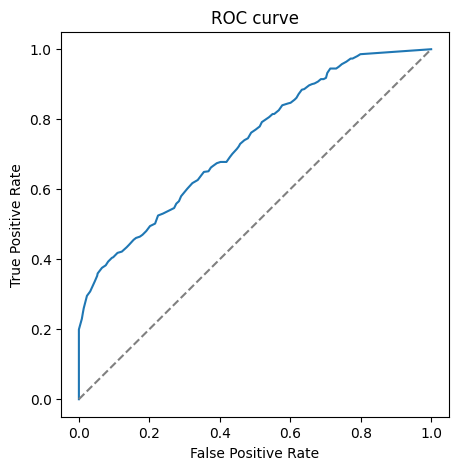

In [34]:
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('DecisionTree', DecisionTreeClassifier())
])

project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "DecisionTree"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "DecisionTree__max_depth": optuna.distributions.IntDistribution(1, 150),
            "DecisionTree__min_samples_split": optuna.distributions.IntDistribution(2, 100),
            "DecisionTree__min_samples_leaf": optuna.distributions.IntDistribution(1, 50),
            "DecisionTree__max_features": optuna.distributions.CategoricalDistribution([None, 'sqrt', 'log2']),
            "DecisionTree__random_state": optuna.distributions.IntDistribution(42, 42),
            "DecisionTree__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced', 'balanced_subsample'])      
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                dt_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("DecisionTree__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "DecisionTree",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

dt_pipeline.set_params(**{f"DecisionTree__{k}": v for k, v in best_params_.items()})
dt_pipeline.fit(X_train, y_train)
y_train_pred_dt = dt_pipeline.predict(X_train)
y_train_proba_dt = dt_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_dt = dt_pipeline.predict(X_test)
y_test_proba_dt = dt_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_dt, y_train_proba_dt)
show_metrics(y_test, y_test_pred_dt, y_test_proba_dt)

## Случайный лес

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.8119    0.7266    0.7669      1313
           1     0.4871    0.6068    0.5404       562

    accuracy                         0.6907      1875
   macro avg     0.6495    0.6667    0.6536      1875
weighted avg     0.7146    0.6907    0.6990      1875

roc_auc_score = 0.7640363406721181


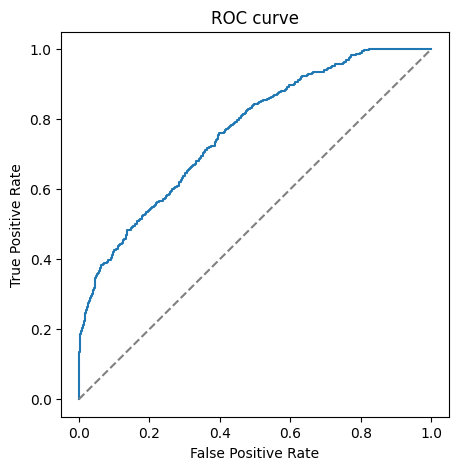

In [35]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "RandomForest"), None)
best_params_ = model_info["params"] if model_info else None
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('RandomForest', RandomForestClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "RandomForest__max_depth": optuna.distributions.IntDistribution(1, 30),
            "RandomForest__min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "RandomForest__min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "RandomForest__max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "RandomForest__n_estimators": optuna.distributions.IntDistribution(20, 500),
            "RandomForest__random_state": optuna.distributions.IntDistribution(42, 42),  
            "RandomForest__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced', 'balanced_subsample'])     
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                rf_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("RandomForest__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "RandomForest",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

rf_pipeline.set_params(**{f"RandomForest__{k}": v for k, v in best_params_.items()})
rf_pipeline.fit(X_train, y_train)
y_train_pred_rf = rf_pipeline.predict(X_train)
y_train_proba_rf = rf_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_rf = rf_pipeline.predict(X_test)
y_test_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_rf, y_train_proba_rf)
show_metrics(y_test, y_test_pred_rf, y_test_proba_rf)

## Градиентный бустинг

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.7757    0.8667    0.8187      1313
           1     0.5711    0.4146    0.4804       562

    accuracy                         0.7312      1875
   macro avg     0.6734    0.6407    0.6496      1875
weighted avg     0.7144    0.7312    0.7173      1875

roc_auc_score = 0.7374109981488157


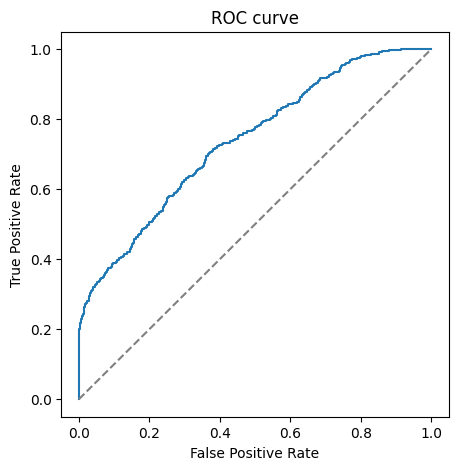

In [36]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('GradientBoosting', GradientBoostingClassifier())
])

model_info = next((p for p in configs if p["model_name"] == "GradientBoosting"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "GradientBoosting__max_depth": optuna.distributions.IntDistribution(1, 10),
            "GradientBoosting__min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "GradientBoosting__min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "GradientBoosting__max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "GradientBoosting__n_estimators": optuna.distributions.IntDistribution(20, 1500, log=True),
            "GradientBoosting__learning_rate": optuna.distributions.FloatDistribution(1e-5, 0.5, log=True),
            "GradientBoosting__random_state": optuna.distributions.IntDistribution(42, 42)     
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                gb_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("GradientBoosting__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "GradientBoosting",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

gb_pipeline.set_params(**{f"GradientBoosting__{k}": v for k, v in best_params_.items()})
gb_pipeline.fit(X_train, y_train)
y_train_pred_gb = gb_pipeline.predict(X_train)
y_train_proba_gb = gb_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_gb = gb_pipeline.predict(X_test)
y_test_proba_gb = gb_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_gb, y_train_proba_gb)
show_metrics(y_test, y_test_pred_gb, y_test_proba_gb)

## CatBoost

              precision    recall  f1-score   support

           0     0.8049    0.7449    0.7737      1313
           1     0.4924    0.5783    0.5319       562

    accuracy                         0.6949      1875
   macro avg     0.6487    0.6616    0.6528      1875
weighted avg     0.7113    0.6949    0.7013      1875

roc_auc_score = 0.7609980132970866


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


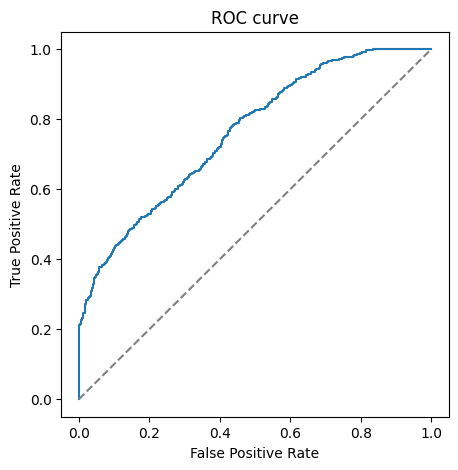

In [37]:
frozen_params = {
     'silent':True,
     'random_state':42
}
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "CatBoost"), None)
best_params_ = model_info["params"] if model_info else None
cb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('CatBoost', CatBoostClassifier(**frozen_params))
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "CatBoost__depth": optuna.distributions.IntDistribution(2, 10),
            "CatBoost__l2_leaf_reg": optuna.distributions.FloatDistribution(1e-2, 15, log=True),
            "CatBoost__iterations": optuna.distributions.IntDistribution(20, 1500, log=True),
            "CatBoost__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.5, log=True),
            "CatBoost__random_strength": optuna.distributions.FloatDistribution(1e-2, 1),
            "CatBoost__auto_class_weights": optuna.distributions.CategoricalDistribution(['None', 'Balanced', 'SqrtBalanced'])     
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                cb_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("CatBoost__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "CatBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

cb_pipeline.set_params(**{f"CatBoost__{k}": v for k, v in best_params_.items()})
cb_pipeline.fit(X_train, y_train)
y_train_pred_cb = cb_pipeline.predict(X_train)
y_train_proba_cb = cb_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_cb = cb_pipeline.predict(X_test)
y_test_proba_cb = cb_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_cb, y_train_proba_cb)
show_metrics(y_test, y_test_pred_cb, y_test_proba_cb)

## XGBoost

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.7720    0.9414    0.8483      1313
           1     0.7190    0.3505    0.4713       562

    accuracy                         0.7643      1875
   macro avg     0.7455    0.6459    0.6598      1875
weighted avg     0.7561    0.7643    0.7353      1875

roc_auc_score = 0.7656307171916206


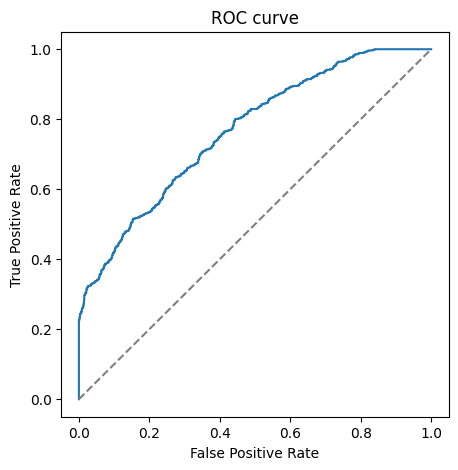

In [38]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "XGBoost"), None)
best_params_ = model_info["params"] if model_info else None
xg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('XGBoost', XGBClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "XGBoost__n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "XGBoost__max_depth": optuna.distributions.IntDistribution(2, 10),
            "XGBoost__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "XGBoost__reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10),
            "XGBoost__random_state": optuna.distributions.IntDistribution(42, 42)    
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                xg_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("XGBoost__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "XGBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

xg_pipeline.set_params(**{f"XGBoost__{k}": v for k, v in best_params_.items()})
xg_pipeline.fit(X_train, y_train)
y_train_pred_xg = xg_pipeline.predict(X_train)
y_train_proba_xg = xg_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_xg = xg_pipeline.predict(X_test)
y_test_proba_xg = xg_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_xg, y_train_proba_xg)
show_metrics(y_test, y_test_pred_xg, y_test_proba_xg)

## LightGBM

[LightGBM] [Warning] min_data_in_leaf is set=92, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=92
[LightGBM] [Warning] feature_fraction is set=0.36126556141002836, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.36126556141002836
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] min_data_in_leaf is set=92, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=92
[LightGBM] [Warning] feature_fraction is set=0.36126556141002836, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.36126556141002836
[LightGBM] [Info] Number of positive: 1551, number of negative: 4074
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000421 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2723
[LightGBM] [Info] Number of data po

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


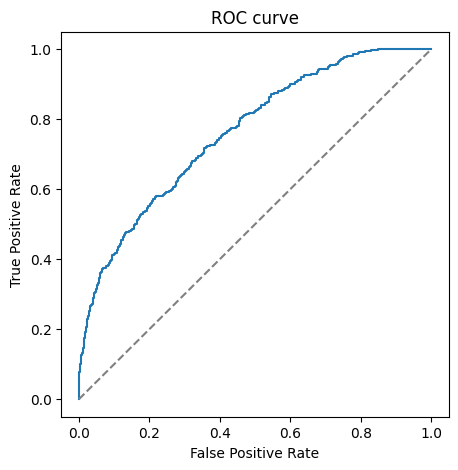

In [39]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "LightGBM"), None)
best_params_ = model_info["params"] if model_info else None
lgbm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('LightGBM', LGBMClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "LightGBM__n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "LightGBM__max_depth": optuna.distributions.IntDistribution(2, 15),
            "LightGBM__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "LightGBM__reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10),
            "LightGBM__num_leaves": optuna.distributions.IntDistribution(7, 255),
            "LightGBM__min_data_in_leaf": optuna.distributions.IntDistribution(20, 100),
            "LightGBM__subsample": optuna.distributions.FloatDistribution(0.8, 1),
            "LightGBM__feature_fraction": optuna.distributions.FloatDistribution(0.3, 1),
            "LightGBM__random_state": optuna.distributions.IntDistribution(42, 42),
            "LightGBM__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced'])
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                lgbm_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("LightGBM__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "LightGBM",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

lgbm_pipeline.set_params(**{f"LightGBM__{k}": v for k, v in best_params_.items()})
lgbm_pipeline.fit(X_train, y_train)
y_train_pred_lgbm = lgbm_pipeline.predict(X_train)
y_train_proba_lgbm = lgbm_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_lgbm = lgbm_pipeline.predict(X_test)
y_test_proba_lgbm = lgbm_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_lgbm, y_train_proba_lgbm)
show_metrics(y_test, y_test_pred_lgbm, y_test_proba_lgbm)

## SVM

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.8079    0.7304    0.7672      1313
           1     0.4855    0.5943    0.5344       562

    accuracy                         0.6896      1875
   macro avg     0.6467    0.6623    0.6508      1875
weighted avg     0.7113    0.6896    0.6974      1875

roc_auc_score = 0.7614547110336547


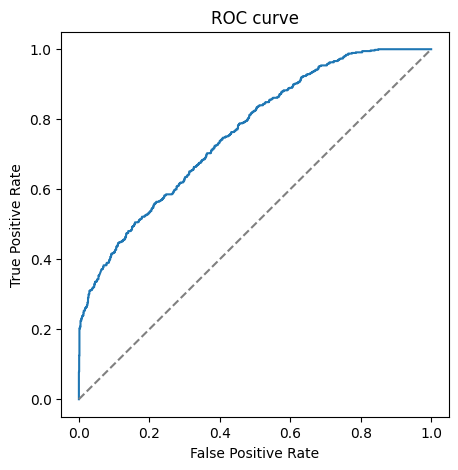

In [40]:
svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('SVM', SVC())
])

project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "SVM"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "SVM__C": optuna.distributions.FloatDistribution(1e-2, 300, log=True),
            "SVM__gamma": optuna.distributions.FloatDistribution(1e-5, 1, log=True),
            "SVM__kernel": optuna.distributions.CategoricalDistribution(['rbf']),
            "SVM__probability": optuna.distributions.CategoricalDistribution([True]),
            "SVM__class_weight": optuna.distributions.CategoricalDistribution(['balanced']),
            "SVM__random_state": optuna.distributions.IntDistribution(42, 42)      
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                svm_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("SVM__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "SVM",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

svm_pipeline.set_params(**{f"SVM__{k}": v for k, v in best_params_.items()})
svm_pipeline.fit(X_train, y_train)
y_train_pred_svm = svm_pipeline.predict(X_train)
y_train_proba_svm = svm_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_svm = svm_pipeline.predict(X_test)
y_test_proba_svm = svm_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_svm, y_train_proba_svm)
show_metrics(y_test, y_test_pred_svm, y_test_proba_svm)

## Сохраним полученные результаты для последующего анализа
(см. error_analisys.ipynb)



In [ ]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
X_test['y_true'] = y_test
X_test['y_pred'] = y_test_pred_log_reg
X_test['y_proba_1'] = y_test_proba_log_reg
X_test['y_proba_0'] = y_test_proba_0_log_reg
output_path = project_root / 'data' / 'interim' / 'X_test_with_predict_proba.csv'
X_test.to_csv(output_path, index=False)

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as 

              precision    recall  f1-score   support

           0     0.8446    0.6664    0.7450      1313
           1     0.4779    0.7135    0.5724       562

    accuracy                         0.6805      1875
   macro avg     0.6613    0.6900    0.6587      1875
weighted avg     0.7347    0.6805    0.6933      1875

roc_auc_score = 0.7735416164118464


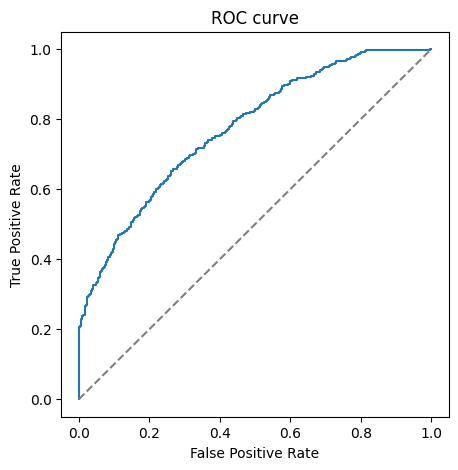

In [56]:
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
log_reg_pipeline_undersampling = make_pipeline( 
    DataCleaner(),
    ohe_step,
    NaNCatboostImputer('Years in current job', 'classification'),
    NaNCatboostImputer('Bankruptcies', 'classification'),
    NaNCatboostImputer('Credit Score', 'regression'),
    NaNCatboostImputer('Annual Income', 'regression'),
    StandardScaler(), BorderlineSMOTE(sampling_strategy=0.65,random_state=42), log_reg_pipeline.named_steps['LogisticRegression']) #0.65
log_reg_pipeline_undersampling.fit(X_train, y_train)
y_train_pred_lru = log_reg_pipeline_undersampling.predict(X_train)
y_train_proba_lru = log_reg_pipeline_undersampling.predict_proba(X_train)[:, 1]

y_test_pred_lru = log_reg_pipeline_undersampling.predict(X_test)
y_test_proba_lru = log_reg_pipeline_undersampling.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_lru, y_train_proba_lru)
show_metrics(y_test, y_test_pred_lru, y_test_proba_lru)